# 3. Geração de Candidatos BAC (Baseline Clássico)

## Objetivo
Implementar um método clássico (filtro de Frangi) para extrair estruturas brilhantes, pequenas e alongadas.

## Requisitos:
1. **Filtro multiescala:** Aplicar filtro de Frangi para obter mapa de resposta contínuo.
2. **Extração de regiões:** Transformar resposta em candidatos.
3. **Características:** Calcular área, comprimento, largura, alongamento e intensidade relativa.
4. **Pontuação:** Favorecer padrões lineares/vasculares (alta excentricidade).
5. **Filtragem:** Remover propostas de fundo/bordas e artefatos. Manter lista de rejeitados.
6. **Top-N:** Selecionar os N melhores candidatos por imagem.

In [1]:
import cv2
import numpy as np
import pandas as pd
import pydicom
import matplotlib.pyplot as plt
from pathlib import Path
from skimage.filters import threshold_otsu, frangi
from skimage.measure import label, regionprops
from skimage.morphology import binary_erosion, disk, closing
import warnings
warnings.filterwarnings('ignore')

## Funções de Pré-processamento
Reaproveitando a lógica anterior para carregar imagens e gerar máscaras.

In [2]:
def load_dicom_normalized(dcm_path):
    ds = pydicom.dcmread(dcm_path)
    image = ds.pixel_array.astype(np.float32)
    if getattr(ds, 'PhotometricInterpretation', 'UNKNOWN') == 'MONOCHROME1':
        image = np.max(image) - image
    norm = (image - np.min(image)) / (np.max(image) - np.min(image) + 1e-8)
    return norm

def get_breast_mask(img_norm):
    img_blur = cv2.GaussianBlur(img_norm, (5, 5), 0)
    pixels = img_blur[img_blur > 0.05]
    if len(pixels) == 0:
         return np.zeros_like(img_blur, dtype=bool)
    thresh = threshold_otsu(pixels)
    binary = img_blur > thresh
    binary = closing(binary, disk(5))
    label_img = label(binary)
    regions = regionprops(label_img)
    if not regions:
         return binary
    largest_region = max(regions, key=lambda r: r.area)
    return (label_img == largest_region.label)

## Geração e Pontuação de Candidatos
Lógica do Filtro Multiescala e extração de características.

In [3]:
def extract_candidates(img_processed, mask, max_candidates=10):
    # 1. Mapa de resposta multiescala (Filtro de Frangi)
    # Procuramos estruturas finas tubulares/brilhantes (BAC).
    # black_ridges=False pois BAC é brilhante (após a inversão de polaridade).
    frangi_map = frangi(img_processed, sigmas=range(1, 5, 1), black_ridges=False)
    
    # 2. Criar regiões candidatas (threshold baixo)
    # Apenas onde a máscara da mama é válida
    frangi_map[~mask] = 0
    valid_frangi = frangi_map[frangi_map > 1e-6]
    
    if len(valid_frangi) == 0:
        return frangi_map, [], []
        
    thresh = threshold_otsu(valid_frangi)
    # Limiar ligeiramente abaixo do Otsu para ser mais abrangente (candidatos)
    binary_candidates = frangi_map > (thresh * 0.5)
    
    # 3. Calcular Características e Pontuação
    label_cand = label(binary_candidates)
    props = regionprops(label_cand, intensity_image=img_processed)
    
    # Definir margem da mama (bordas) para filtro
    # Erodindo a mascara em 15 pixels para definir a zona segura
    safe_mask = binary_erosion(mask, disk(15))
    
    accepted = []
    rejected = []
    
    for p in props:
        # Pular regiões mínimas de 1 ou 2 pixels para evitar ruído extremo
        if p.area < 3:
            continue
            
        area = p.area
        length = p.axis_major_length
        width = p.axis_minor_length
        elongation = p.eccentricity  # 0 a 1 (1 = totalmente linear)
        mean_intensity = p.intensity_mean
        
        # Intensidade Relativa
        min_r, min_c, max_r, max_c = p.bbox
        # Expande bbox em 5 pixels
        min_r_exp = max(0, min_r - 5)
        min_c_exp = max(0, min_c - 5)
        max_r_exp = min(img_processed.shape[0], max_r + 5)
        max_c_exp = min(img_processed.shape[1], max_c + 5)
        
        surrounding = img_processed[min_r_exp:max_r_exp, min_c_exp:max_c_exp]
        surround_mean = np.mean(surrounding)
        relative_intensity = mean_intensity / (surround_mean + 1e-8)
        
        # Verificação se o centróide está muito perto da borda (fora da safe_mask)
        r_cent, c_cent = int(p.centroid[0]), int(p.centroid[1])
        near_edge = not safe_mask[r_cent, c_cent]
        
        cand_data = {
            'bbox': p.bbox,
            'centroid': p.centroid,
            'area': area,
            'length': length,
            'width': width,
            'elongation': elongation,
            'mean_intensity': mean_intensity,
            'relative_intensity': relative_intensity
        }
        
        # Filtros de exclusão
        if area < 10:
            cand_data['reason'] = 'Area muito pequena (<10)'
            rejected.append(cand_data)
            continue
        if near_edge:
            cand_data['reason'] = 'Localizado na borda externa da mama'
            rejected.append(cand_data)
            continue
        if elongation < 0.8:
            cand_data['reason'] = 'Morfologia nao linear/tubular (excentricidade baixa)'
            rejected.append(cand_data)
            continue
        
        # Pontuação: favorece estrutura linear (alongamento) e brilhante.
        # Dá bônus leve se a largura for consistente com vaso (2-6 pixels em res 1024)
        width_score = 1.0 if 2 <= width <= 6 else 0.5
        cand_data['score'] = (elongation * 0.5) + (min(relative_intensity, 3.0) / 3.0 * 0.4) + (width_score * 0.1)
        
        accepted.append(cand_data)
        
    # Ordenar por pontuação e manter top N
    accepted = sorted(accepted, key=lambda x: x['score'], reverse=True)
    top_candidates = accepted[:max_candidates]
    
    # Aqueles que passaram mas não entraram no top N vão para rejeitados
    for cand in accepted[max_candidates:]:
        cand['reason'] = 'Fora do top N de score'
        rejected.append(cand)
        
    return frangi_map, top_candidates, rejected

## Execução no Lote
Para cada imagem, geramos o mapa, ranqueamos candidatos e demonstramos os aceitos.


--- Analisando Imagem: 51049276 ---
Processando Frangi Multiescala...
Candidatos Aceitos: 1 | Rejeitados: 9


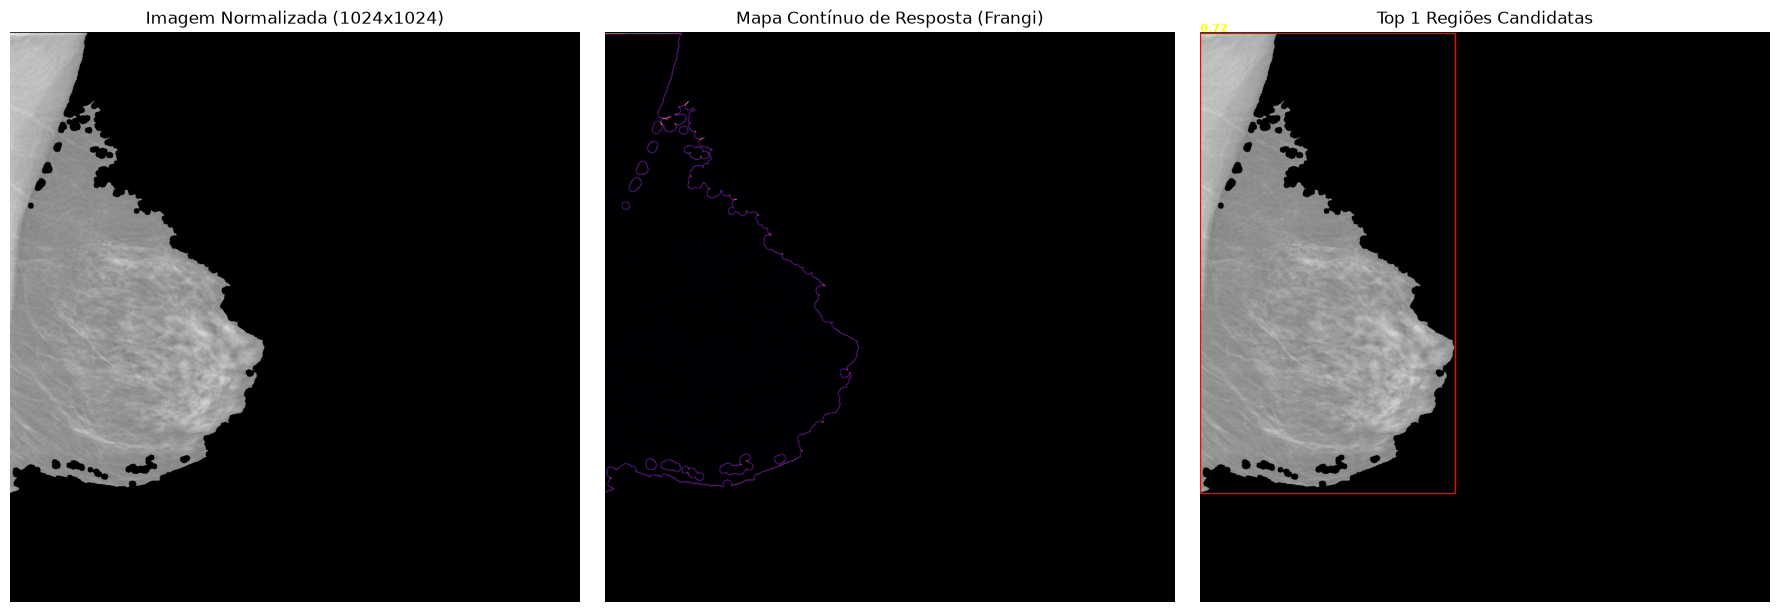


--- Analisando Imagem: 50996709 ---
Processando Frangi Multiescala...
Candidatos Aceitos: 0 | Rejeitados: 23


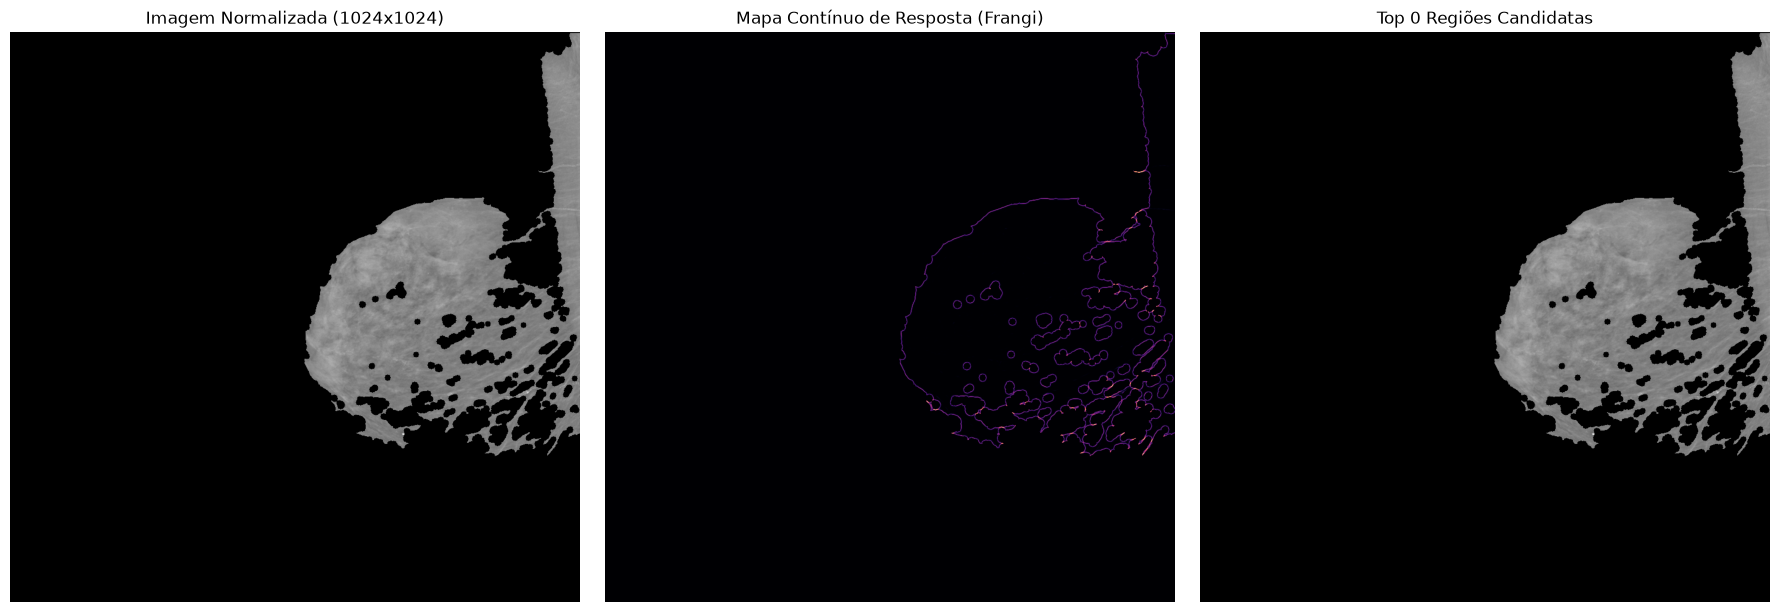


--- Analisando Imagem: 20587928 ---
Processando Frangi Multiescala...
Candidatos Aceitos: 1 | Rejeitados: 4


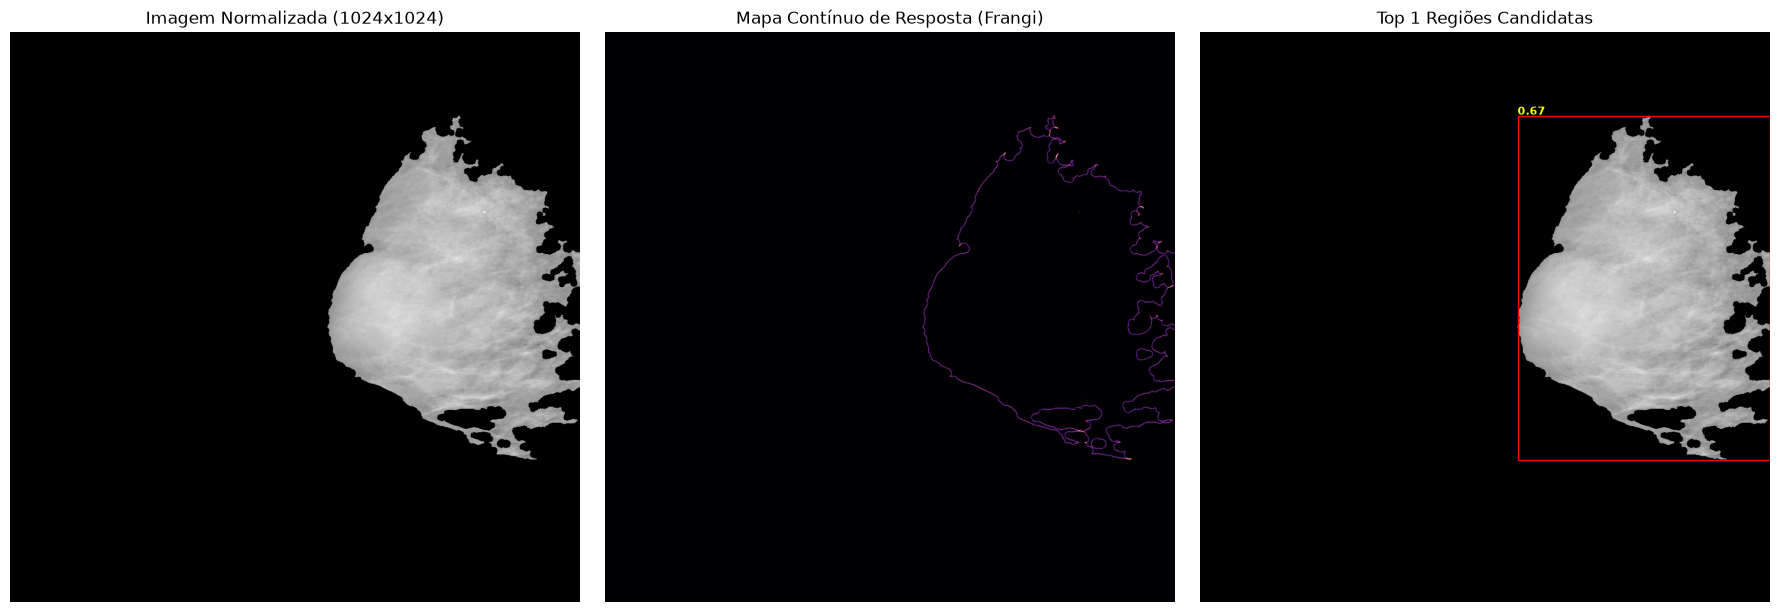


--- Analisando Imagem: 53587104 ---
Processando Frangi Multiescala...
Candidatos Aceitos: 1 | Rejeitados: 3


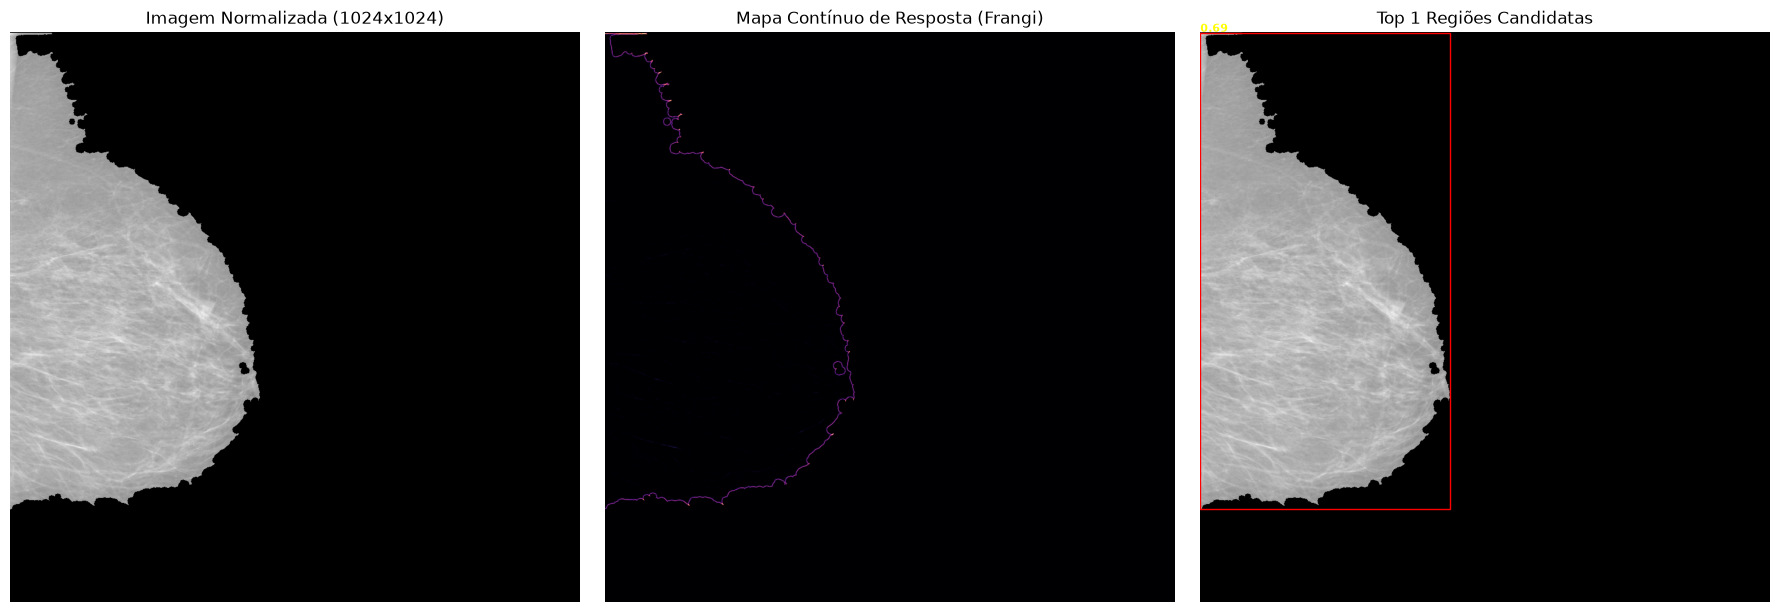


--- Analisando Imagem: 20588216 ---
Processando Frangi Multiescala...
Candidatos Aceitos: 1 | Rejeitados: 13


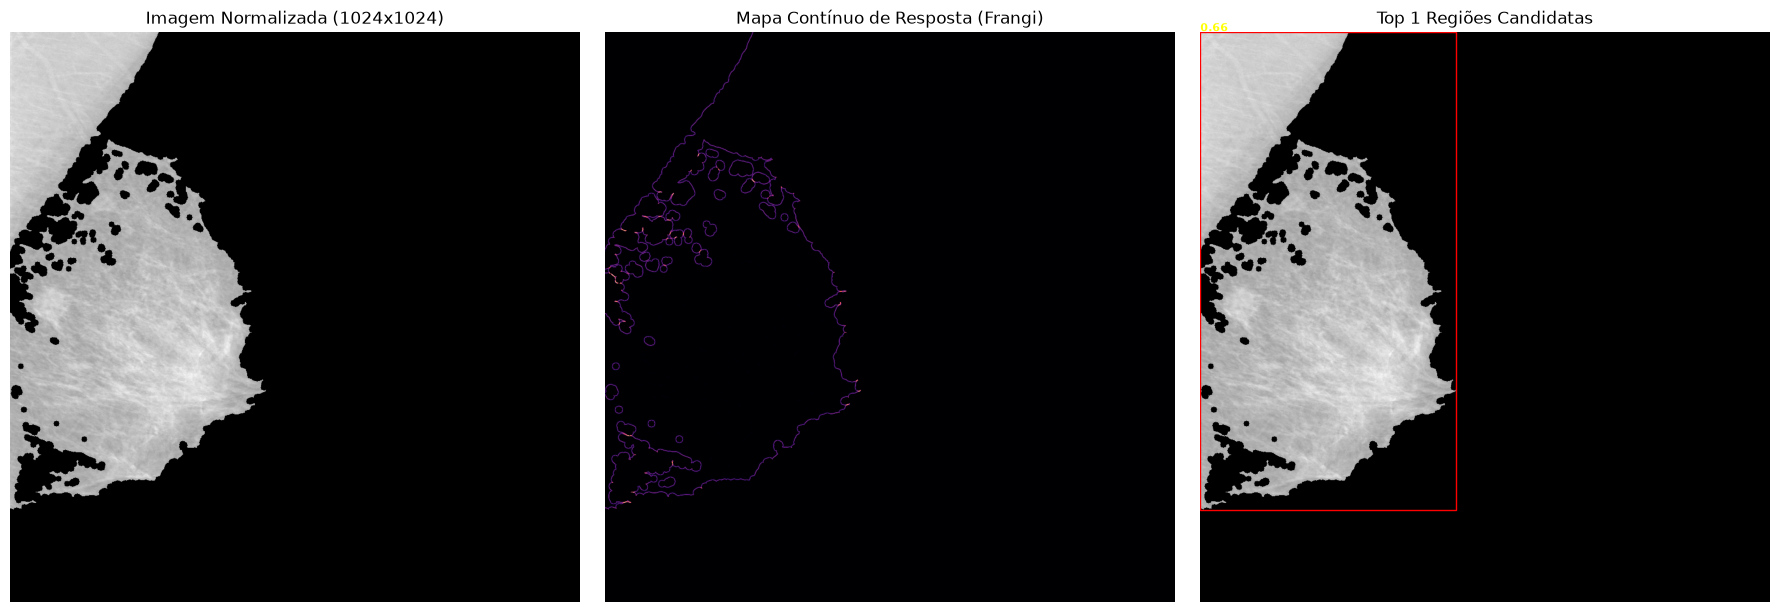

In [4]:
import matplotlib.patches as patches

manifest_path = Path('../../data/interim/inbreast_batch1_ml_manifest.csv')
df_batch = pd.read_csv(manifest_path)

all_candidates = []
all_rejected = []

for idx, row in df_batch.iterrows():
    print(f"\n--- Analisando Imagem: {row['image_id']} ---")
    
    img_norm = load_dicom_normalized(row['dcm_path'])
    # Para o teste rápido do Frangi, vamos redimensionar para 1024x1024 antes 
    # para simular o tamanho de processamento padrão do modelo final
    img_resized = cv2.resize(img_norm, (1024, 1024), interpolation=cv2.INTER_AREA)
    mask = get_breast_mask(img_resized)
    img_processed = img_resized.copy()
    img_processed[~mask] = 0
    
    print("Processando Frangi Multiescala...")
    frangi_map, accepted, rejected = extract_candidates(img_processed, mask, max_candidates=15)
    
    print(f"Candidatos Aceitos: {len(accepted)} | Rejeitados: {len(rejected)}")
    
    # Registrar dados
    for i, c in enumerate(accepted):
        c['image_id'] = row['image_id']
        c['rank'] = i + 1
        all_candidates.append(c)
        
    for c in rejected:
        c['image_id'] = row['image_id']
        all_rejected.append(c)
    
    # --- PLOT ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    axes[0].imshow(img_processed, cmap='gray')
    axes[0].set_title(f"Imagem Normalizada (1024x1024)")
    axes[0].axis('off')
    
    axes[1].imshow(frangi_map, cmap='magma')
    axes[1].set_title("Mapa Contínuo de Resposta (Frangi)")
    axes[1].axis('off')
    
    # Plot sobreposto
    axes[2].imshow(img_processed, cmap='gray')
    axes[2].set_title(f"Top {len(accepted)} Regiões Candidatas")
    axes[2].axis('off')
    
    for c in accepted:
        min_r, min_c, max_r, max_c = c['bbox']
        rect = patches.Rectangle((min_c, min_r), max_c - min_c, max_r - min_r, 
                                 linewidth=1, edgecolor='r', facecolor='none')
        axes[2].add_patch(rect)
        # Adicionar texto do score
        axes[2].text(min_c, min_r-2, f"{c['score']:.2f}", color='yellow', fontsize=8, weight='bold')

    plt.tight_layout()
    plt.show()

## Salvando Resultados do Baseline Clássico
Os resultados tabulares contêm a lista ranqueada de candidatos BAC e também o histórico de propostas rejeitadas.

In [5]:
# Opcional: salvar os candidatos gerados
if all_candidates:
    df_cand = pd.DataFrame(all_candidates)
    df_cand.to_csv('../../data/interim/baseline_candidates.csv', index=False)
    print("Candidatos aceitos (amostra):")
    display(df_cand[['image_id', 'rank', 'score', 'area', 'elongation']].head(10))
else:
    print("Nenhum candidato BAC aceito nestas imagens.")

if all_rejected:
    df_rej = pd.DataFrame(all_rejected)
    df_rej.to_csv('../../data/interim/baseline_rejected.csv', index=False)
    print("\nMotivos comuns de rejeição:")
    display(df_rej['reason'].value_counts())


Candidatos aceitos (amostra):


,image_id,rank,score,area,elongation
0,51049276,1,0.721436,4707.0,0.914314
1,20587928,1,0.665903,5657.0,0.820867
2,53587104,1,0.694336,3855.0,0.913376
3,20588216,1,0.663471,9770.0,0.814092



Motivos comuns de rejeição:


reason
Localizado na borda externa da mama                     47
Area muito pequena (<10)                                 4
Morfologia nao linear/tubular (excentricidade baixa)     1
Name: count, dtype: int64